# Nonlinear Benchmark and Model Interpretability

This notebook benchmarks the expanded logistic regression against one nonlinear model: histogram gradient boosting. It uses the same fixed held-out test set and final NHIS survey weights for performance evaluation. Because NHIS is cross-sectional, these are retrospective classification benchmarks rather than prospective forecasts.

The goal is not to build a large model zoo. The goal is to test whether nonlinear interactions materially improve risk ranking, then examine calibration and which input features matter most for prediction.

> **Data source:** National Center for Health Statistics, National Health Interview Survey, 2025. Analyses, interpretations, and conclusions are those of the author and not NCHS. Raw public-use microdata are not stored in the Git repository.


In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if not (ROOT / "data").exists():
    ROOT = ROOT.parent

PROCESSED = ROOT / "data" / "processed"
ASSETS = ROOT / "assets"
ASSETS.mkdir(exist_ok=True)

metrics = pd.read_csv(PROCESSED / "model_metrics.csv")
importance = pd.read_csv(PROCESSED / "boosting_permutation_importance.csv")
calibration = pd.read_csv(PROCESSED / "boosting_calibration.csv")
deciles = pd.read_csv(PROCESSED / "boosting_risk_deciles.csv")
predictions = pd.read_csv(PROCESSED / "test_predictions.csv", dtype={"HHX": str})

pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
metrics

,model,weighted_roc_auc,weighted_average_precision,weighted_brier_score,weighted_log_loss,weighted_precision_at_0_5,weighted_recall_at_0_5,weighted_specificity_at_0_5,weighted_f1_at_0_5,weighted_balanced_accuracy_at_0_5,unweighted_roc_auc,unweighted_average_precision
0,prevalence_baseline,0.5000,0.0720,0.0668,0.2587,0.0000,0.0000,1.0000,0.0000,0.5000,0.5000,0.0651
1,core_logistic,0.7382,0.2306,0.0612,0.2296,0.3793,0.0137,0.9983,0.0264,0.5060,0.7232,0.2011
2,expanded_logistic,0.7729,0.2719,0.0599,0.2221,0.5788,0.0774,0.9956,0.1366,0.5365,0.7728,0.2439
3,expanded_gradient_boosting,0.7807,0.2667,0.0599,0.2205,0.6571,0.0377,0.9985,0.0713,0.5181,0.7913,0.2370


## Held-out benchmark

The nonlinear benchmark is evaluated on exactly the same held-out adults as the logistic models. Weighted ROC-AUC measures ranking discrimination, average precision is especially useful for the uncommon positive outcome, and Brier score/log loss assess probability quality.

In [2]:
benchmark = metrics.loc[metrics["model"].isin([
    "core_logistic",
    "expanded_logistic",
    "expanded_gradient_boosting",
]), ["model", "weighted_roc_auc", "weighted_average_precision", "weighted_brier_score", "weighted_log_loss"]].copy()
benchmark

,model,weighted_roc_auc,weighted_average_precision,weighted_brier_score,weighted_log_loss
1,core_logistic,0.7382,0.2306,0.0612,0.2296
2,expanded_logistic,0.7729,0.2719,0.0599,0.2221
3,expanded_gradient_boosting,0.7807,0.2667,0.0599,0.2205


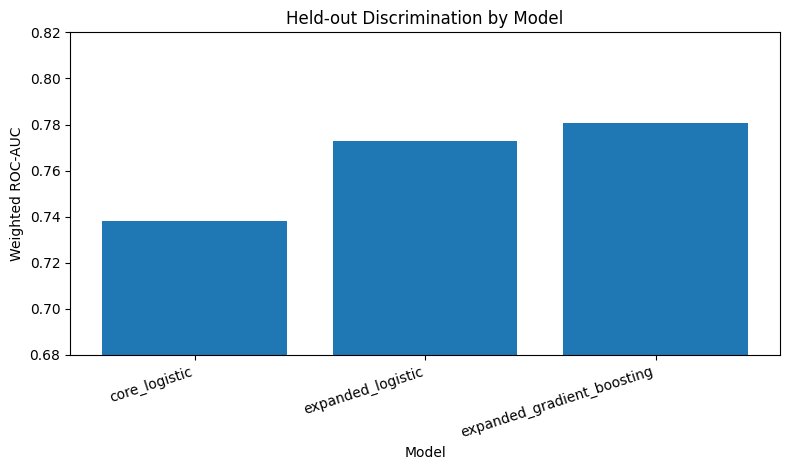

In [3]:
plot_data = benchmark.set_index("model")["weighted_roc_auc"]
plt.figure(figsize=(8, 4.8))
plt.bar(plot_data.index, plot_data.values)
plt.ylabel("Weighted ROC-AUC")
plt.xlabel("Model")
plt.title("Held-out Discrimination by Model")
plt.ylim(0.68, 0.82)
plt.xticks(rotation=18, ha="right")
plt.tight_layout()
plt.savefig(ASSETS / "nonlinear_model_roc_auc.png", dpi=160, bbox_inches="tight")
plt.show()

The gradient-boosting model provides a modest ROC-AUC improvement over expanded logistic regression, while average precision remains essentially tied. This suggests that nonlinear structure exists, but the simpler logistic model remains highly competitive.

## Permutation importance

Permutation importance is calculated on the held-out test set using weighted ROC-AUC. Each original input feature is shuffled while the others are left unchanged. A larger decline in ROC-AUC indicates that the fitted model relies more heavily on that feature for ranking risk. These are predictive importance measures, not causal effects.

In [4]:
importance.head(12)

,feature,importance_mean,importance_sd
0,insurance_status,0.0837,0.0083
1,age,0.0734,0.0090
2,functioning_difficulty,0.0298,0.0033
3,general_health,0.0258,0.0042
4,housing_tenure,0.0065,0.0032
5,sex,0.0058,0.0025
6,usual_place_care,0.0049,0.0015
7,race_ethnicity,0.0022,0.0013
8,education,0.0014,0.0013
9,marital_status,0.0013,0.0019


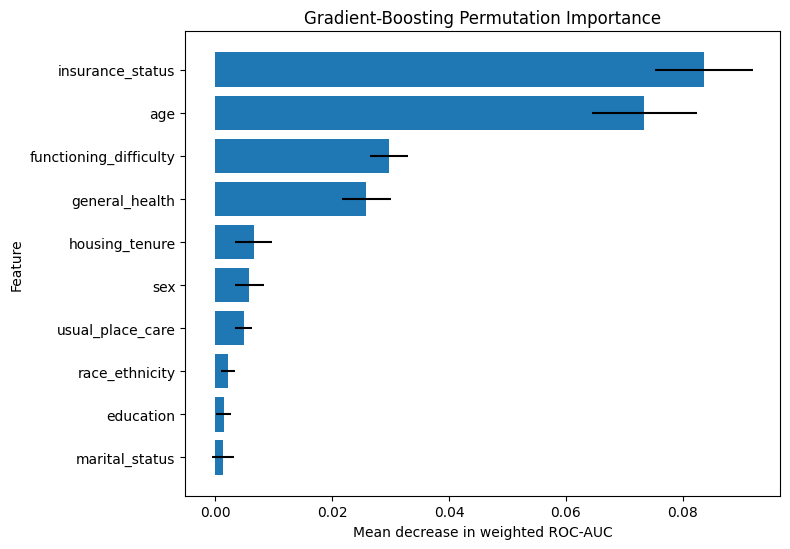

In [5]:
top_importance = importance.head(10).sort_values("importance_mean")
plt.figure(figsize=(8, 5.6))
plt.barh(top_importance["feature"], top_importance["importance_mean"], xerr=top_importance["importance_sd"])
plt.xlabel("Mean decrease in weighted ROC-AUC")
plt.ylabel("Feature")
plt.title("Gradient-Boosting Permutation Importance")
plt.tight_layout()
plt.savefig(ASSETS / "boosting_permutation_importance.png", dpi=160, bbox_inches="tight")
plt.show()

## Weighted calibration

The held-out sample is divided into ten equally sized bins by predicted probability. Within each bin, the weighted mean predicted probability is compared with the weighted observed prevalence.

In [6]:
calibration

,risk_bin,rows,weighted_mean_predicted_probability,weighted_observed_prevalence
0,1,601,0.0091,0.0087
1,2,601,0.0149,0.0265
2,3,600,0.0202,0.0148
3,4,601,0.0253,0.0141
4,5,600,0.0317,0.0470
5,6,601,0.0400,0.0402
6,7,600,0.0513,0.0524
7,8,601,0.0726,0.0772
8,9,600,0.1208,0.1268
9,10,601,0.2734,0.2652


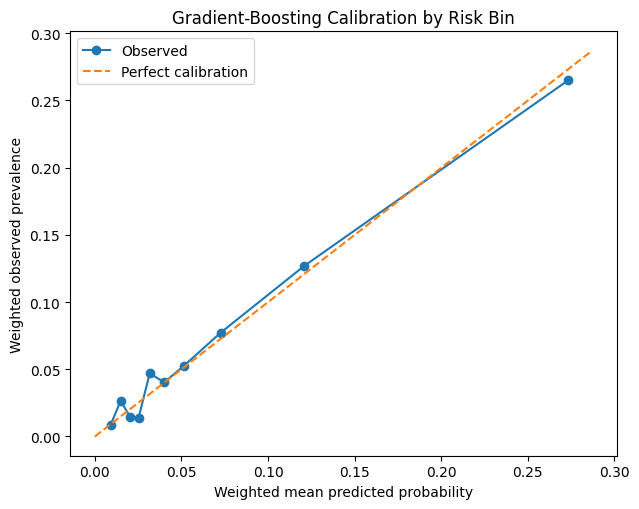

In [7]:
plt.figure(figsize=(6.5, 5.2))
plt.plot(calibration["weighted_mean_predicted_probability"], calibration["weighted_observed_prevalence"], marker="o", label="Observed")
limit = max(calibration["weighted_mean_predicted_probability"].max(), calibration["weighted_observed_prevalence"].max()) * 1.05
plt.plot([0, limit], [0, limit], linestyle="--", label="Perfect calibration")
plt.xlabel("Weighted mean predicted probability")
plt.ylabel("Weighted observed prevalence")
plt.title("Gradient-Boosting Calibration by Risk Bin")
plt.legend()
plt.tight_layout()
plt.savefig(ASSETS / "boosting_calibration.png", dpi=160, bbox_inches="tight")
plt.show()

## Risk concentration

For a rare outcome, risk ranking can be more informative than classifying everyone at an arbitrary 0.50 cutoff. The table below orders the held-out sample from highest to lowest predicted risk and summarizes ten equally sized risk groups.

In [8]:
deciles

,risk_decile,rows,weighted_mean_predicted_probability,weighted_observed_prevalence,weighted_positive_share,cumulative_weighted_positive_share
0,1,601,0.2734,0.2652,0.4240,0.4240
1,2,601,0.1207,0.1267,0.1855,0.6096
2,3,600,0.0726,0.0773,0.1121,0.7216
3,4,601,0.0513,0.0524,0.0764,0.7980
4,5,600,0.0400,0.0402,0.0557,0.8537
5,6,601,0.0317,0.0476,0.0643,0.9180
6,7,600,0.0253,0.0134,0.0185,0.9364
7,8,601,0.0202,0.0148,0.0211,0.9575
8,9,600,0.0149,0.0265,0.0322,0.9898
9,10,601,0.0091,0.0087,0.0102,1.0000


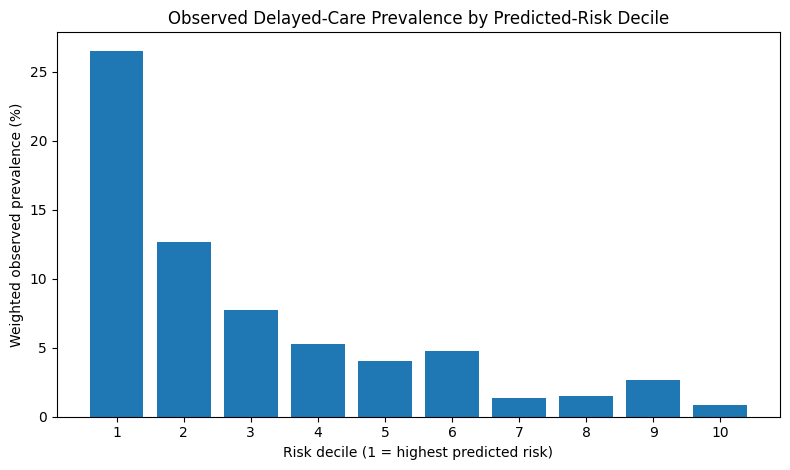

In [9]:
plt.figure(figsize=(8, 4.8))
plt.bar(deciles["risk_decile"], deciles["weighted_observed_prevalence"] * 100)
plt.xlabel("Risk decile (1 = highest predicted risk)")
plt.ylabel("Weighted observed prevalence (%)")
plt.title("Observed Delayed-Care Prevalence by Predicted-Risk Decile")
plt.xticks(deciles["risk_decile"])
plt.tight_layout()
plt.savefig(ASSETS / "boosting_risk_deciles.png", dpi=160, bbox_inches="tight")
plt.show()

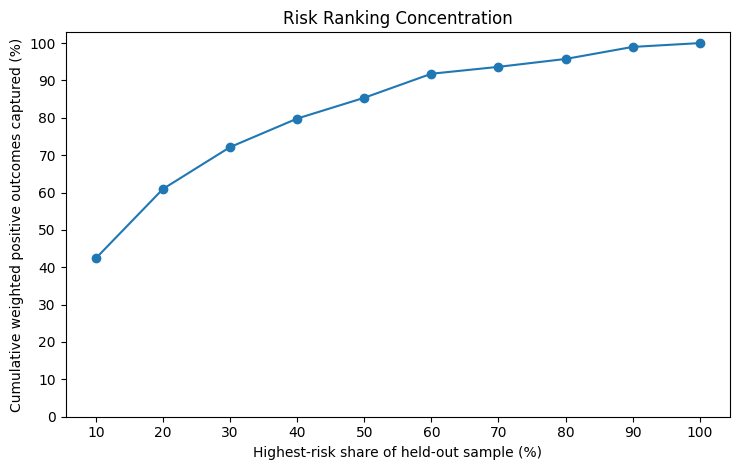

In [10]:
capture = deciles.copy()
capture["top_sample_share_pct"] = capture["risk_decile"] * 10
capture["cumulative_positive_capture_pct"] = capture["cumulative_weighted_positive_share"] * 100
plt.figure(figsize=(7.5, 4.8))
plt.plot(capture["top_sample_share_pct"], capture["cumulative_positive_capture_pct"], marker="o")
plt.xlabel("Highest-risk share of held-out sample (%)")
plt.ylabel("Cumulative weighted positive outcomes captured (%)")
plt.title("Risk Ranking Concentration")
plt.xticks(capture["top_sample_share_pct"])
plt.yticks(np.arange(0, 101, 10))
plt.tight_layout()
plt.savefig(ASSETS / "boosting_positive_capture.png", dpi=160, bbox_inches="tight")
plt.show()

In [11]:
expanded = benchmark.set_index("model").loc["expanded_logistic"]
boosting = benchmark.set_index("model").loc["expanded_gradient_boosting"]
summary = {
    "roc_auc_gain_vs_expanded_logistic": boosting["weighted_roc_auc"] - expanded["weighted_roc_auc"],
    "average_precision_change_vs_expanded_logistic": boosting["weighted_average_precision"] - expanded["weighted_average_precision"],
    "brier_score_change_vs_expanded_logistic": boosting["weighted_brier_score"] - expanded["weighted_brier_score"],
    "top_10_percent_positive_capture": deciles.loc[deciles["risk_decile"] == 1, "weighted_positive_share"].iloc[0],
    "top_20_percent_positive_capture": deciles.loc[deciles["risk_decile"] == 2, "cumulative_weighted_positive_share"].iloc[0],
    "highest_risk_decile_observed_prevalence": deciles.loc[deciles["risk_decile"] == 1, "weighted_observed_prevalence"].iloc[0],
}
pd.Series(summary)

roc_auc_gain_vs_expanded_logistic                0.0078
average_precision_change_vs_expanded_logistic   -0.0051
brier_score_change_vs_expanded_logistic         -0.0000
top_10_percent_positive_capture                  0.4240
top_20_percent_positive_capture                  0.6096
highest_risk_decile_observed_prevalence          0.2652
dtype: float64

## Subgroup diagnostics

Held-out subgroup diagnostics are reported for sex, race/ethnicity, and nativity for the expanded logistic and gradient-boosting models. These values are included to make model behavior across groups inspectable. Small subgroups can have very unstable discrimination and calibration metrics, so the table reports sample sizes and positive counts and should **not** be read as a formal fairness determination.

In [12]:
subgroups = pd.read_csv(PROCESSED / "model_subgroup_metrics.csv")
review = subgroups[[
    "dimension",
    "level",
    "model",
    "unweighted_n",
    "unweighted_positives",
    "weighted_prevalence",
    "weighted_mean_predicted_probability",
    "weighted_calibration_gap",
    "weighted_roc_auc",
    "weighted_average_precision",
]].copy()
review[[
    "weighted_prevalence",
    "weighted_mean_predicted_probability",
    "weighted_calibration_gap",
    "weighted_roc_auc",
    "weighted_average_precision",
]] = review[[
    "weighted_prevalence",
    "weighted_mean_predicted_probability",
    "weighted_calibration_gap",
    "weighted_roc_auc",
    "weighted_average_precision",
]].round(3)
review.sort_values(["dimension", "level", "model"])

,dimension,level,model,unweighted_n,unweighted_positives,weighted_prevalence,weighted_mean_predicted_probability,weighted_calibration_gap,weighted_roc_auc,weighted_average_precision
19,Nativity,Born outside U.S./territory,expanded_gradient_boosting,982,65,0.0780,0.0670,-0.0110,0.7720,0.2710
18,Nativity,Born outside U.S./territory,expanded_logistic,982,65,0.0780,0.0690,-0.0080,0.7990,0.3040
21,Nativity,U.S. or U.S. territory born,expanded_gradient_boosting,4894,314,0.0700,0.0720,0.0010,0.7900,0.2730
20,Nativity,U.S. or U.S. territory born,expanded_logistic,4894,314,0.0700,0.0720,0.0020,0.7730,0.2700
5,Race/ethnicity,Hispanic,expanded_gradient_boosting,807,74,0.0940,0.0940,-0.0000,0.8280,0.3790
4,Race/ethnicity,Hispanic,expanded_logistic,807,74,0.0940,0.0930,-0.0010,0.8390,0.3830
7,Race/ethnicity,Non-Hispanic AIAN,expanded_gradient_boosting,43,3,0.0260,0.1270,0.1000,0.5790,0.0520
6,Race/ethnicity,Non-Hispanic AIAN,expanded_logistic,43,3,0.0260,0.1170,0.0910,0.5310,0.0500
9,Race/ethnicity,Non-Hispanic AIAN and another group,expanded_gradient_boosting,36,3,0.1220,0.1070,-0.0150,0.4880,0.1700
8,Race/ethnicity,Non-Hispanic AIAN and another group,expanded_logistic,36,3,0.1220,0.1380,0.0160,0.2950,0.1520


## Interpretation and limitations

The nonlinear model improves weighted ROC-AUC and probability-loss metrics only modestly, while expanded logistic regression retains slightly higher average precision. That makes the models complementary rather than establishing a universal winner.

Permutation importance indicates which features the fitted boosting model relies on for prediction; it does **not** establish causality, fairness, or policy priority. Risk-decile results are descriptive of this fixed held-out cross-sectional sample and are not an operational screening threshold or a forecast of future outcomes. Any real-world use would require prospective validation, explicit threshold selection, subgroup performance review, and assessment of the consequences of false positives and false negatives.